<a href="https://colab.research.google.com/github/anupbagale/csv-data-to-image/blob/main/notebooks/02_image_to_csv_with_pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image to CSV with pandas

The same round trip as notebook 01, this time with a pandas `DataFrame`. pandas adds row and
column labels to the data, and that is where most mistakes with this method come from.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

os.makedirs("output", exist_ok=True)   # the CSV and image files are written here
import pandas as pd

In [2]:
image = data.camera()
df = pd.DataFrame(image)
df.iloc[:5, :8]

,0,1,2,3,4,5,6,7
0,200,200,200,200,199,200,199,198
1,200,199,199,200,199,200,199,198
2,199,199,199,200,200,200,200,200
3,200,200,199,199,199,199,199,199
4,200,200,200,200,199,199,199,200


## Writing and reading

`to_csv` writes the column labels (0, 1, 2, ...) as the first line. With `index=False` it leaves
out the row labels. `read_csv` then uses the first line as column names, so the numbers that come
back are exactly the pixel values.

In [3]:
csv_path = "output/camera_pandas.csv"
df.to_csv(csv_path, index=False)

restored = pd.read_csv(csv_path).to_numpy().astype(np.uint8)
print("shape:", restored.shape)
print("identical to the original:", np.array_equal(restored, image))

shape: (512, 512)
identical to the original: True


## Two common mistakes

Forgetting `index=False` writes the row numbers as an extra first column. Reading with
`header=None` treats the line of column labels as an extra row of pixels. Both change the shape of
the image:

In [4]:
df.to_csv("output/with_index.csv")              # index=True is the default
with_index = pd.read_csv("output/with_index.csv").to_numpy()
header_as_row = pd.read_csv(csv_path, header=None).to_numpy()

print("correct:              ", restored.shape)
print("written with index:   ", with_index.shape, " <- one extra column")
print("read with header=None:", header_as_row.shape, " <- one extra row")

correct:               (512, 512)
written with index:    (512, 513)  <- one extra column
read with header=None: (513, 512)  <- one extra row


## Displaying the result

The first version of this notebook showed three images: the original, an "image without merging"
and one passed through `cv2.merge`. They looked the same because they are the same.
`cv2.merge([a])` with a single array just returns that array, so it is not needed here.

The images also came out in yellow and purple instead of grey. That has nothing to do with the
CSV file: `plt.imshow` colours single-channel arrays with its default colour map (viridis) unless
it is told to use `cmap="gray"`.

cv2.merge([restored]) is the same array: True


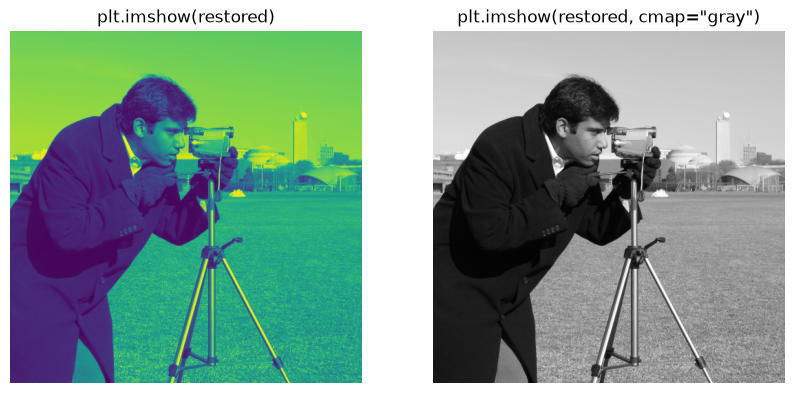

In [5]:
print("cv2.merge([restored]) is the same array:", np.array_equal(cv2.merge([restored]), restored))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(restored)
ax[0].set_title("plt.imshow(restored)")
ax[1].imshow(restored, cmap="gray")
ax[1].set_title('plt.imshow(restored, cmap="gray")')
for a in ax:
    a.axis("off")
plt.show()